In [2]:
import pandas as pd
import numpy as np
from google.colab import files
uploaded=files.upload()

df = pd.read_excel("PCOS_data_without_infertility.xlsx",
                   sheet_name="Full_new")

df.head()

Saving PCOS_data_without_infertility.xlsx to PCOS_data_without_infertility.xlsx


,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),...,Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm),Unnamed: 44
0,1,1,0,28,44.6,152.0,19.300000,15,78,22,...,1.0,0,110,80,3,3,18.0,18.0,8.5,NaN
1,2,2,0,36,65.0,161.5,24.921163,15,74,20,...,0.0,0,120,70,3,5,15.0,14.0,3.7,NaN
2,3,3,1,33,68.8,165.0,25.270891,11,72,18,...,1.0,0,120,80,13,15,18.0,20.0,10.0,NaN
3,4,4,0,37,65.0,148.0,29.674945,13,72,20,...,0.0,0,120,70,2,2,15.0,14.0,7.5,NaN
4,5,5,0,25,52.0,161.0,20.060954,11,72,18,...,0.0,0,120,80,3,4,16.0,14.0,7.0,NaN


In [3]:
df.shape

(541, 45)

In [4]:
df.info

<bound method DataFrame.info of      Sl. No  Patient File No.  PCOS (Y/N)   Age (yrs)  Weight (Kg)  \
0         1                 1           0          28         44.6   
1         2                 2           0          36         65.0   
2         3                 3           1          33         68.8   
3         4                 4           0          37         65.0   
4         5                 5           0          25         52.0   
..      ...               ...         ...         ...          ...   
536     537               537           0          35         50.0   
537     538               538           0          30         63.2   
538     539               539           0          36         54.0   
539     540               540           0          27         50.0   
540     541               541           1          23         82.0   

     Height(Cm)         BMI  Blood Group  Pulse rate(bpm)   RR (breaths/min)  \
0        152.000  19.300000           15                78                22   
1        161.500  24.921163           15                74                20   
2        165.000  25.270891           11                72                18   
3        148.000  29.674945           13                72                20   
4        161.000  20.060954           11                72                18   
..           ...        ...          ...               ...               ...   
536      164.592  18.500000           17                72                16   
537      158.000  25.300000           15                72                18   
538      152.000  23.400000           13                74                20   
539      150.000  22.200000           15                74                20   
540      165.000  30.100000           13                80                20   

     ...  Fast food (Y/N)  Reg.Exercise(Y/N)  BP _Systolic (mmHg)  \
0    ...              1.0                  0                  110   
1    ...              0.0                  0                  120   
2    ...              1.0                  0                  120   
3    ...              0.0                  0                  120   
4    ...              0.0                  0                  120   
..   ...              ...                ...                  ...   
536  ...              0.0                  0                  110   
537  ...              0.0                  0                  110   
538  ...              0.0                  0                  110   
539  ...              0.0                  0                  110   
540  ...              1.0                  0                  120   

     BP _Diastolic (mmHg)  Follicle No. (L)  Follicle No. (R)  \
0                      80                 3                 3   
1                      70                 3                 5   
2                      80                13                15   
3                      70                 2                 2   
4                      80                 3                 4   
..                    ...               ...               ...   
536                    70                 1                 0   
537                    70                 9                 7   
538                    80                 1                 0   
539                    70                 7                 6   
540                    70                 9                10   

     Avg. F size (L) (mm) Avg. F size (R) (mm)  Endometrium (mm)  Unnamed: 44  
0                    18.0                 18.0               8.5          NaN  
1                    15.0                 14.0               3.7          NaN  
2                    18.0                 20.0              10.0          NaN  
3                    15.0                 14.0               7.5          NaN  
4                    16.0                 14.0               7.0          NaN  
..                    ...                  ...               ...          ..

In [5]:
# Count missing values in each column
df.isnull().sum()

,0
Sl. No,0
Patient File No.,0
PCOS (Y/N),0
Age (yrs),0
Weight (Kg),0
Height(Cm),0
BMI,0
Blood Group,0
Pulse rate(bpm),0
RR (breaths/min),0


In [6]:
# Display only columns that contain missing values
df.isnull().sum()[df.isnull().sum() > 0]

,0
Marraige Status (Yrs),1
Fast food (Y/N),1
Unnamed: 44,539


In [7]:
# Count duplicate rows
df.duplicated().sum()

np.int64(0)

In [8]:
# Count PCOS-positive and PCOS-negative cases
df["PCOS (Y/N)"].value_counts()

,count
PCOS (Y/N),
0,364
1,177


<Axes: title={'center': 'Distribution of PCOS Cases'}, xlabel='PCOS (0 = No, 1 = Yes)', ylabel='Number of Patients'>

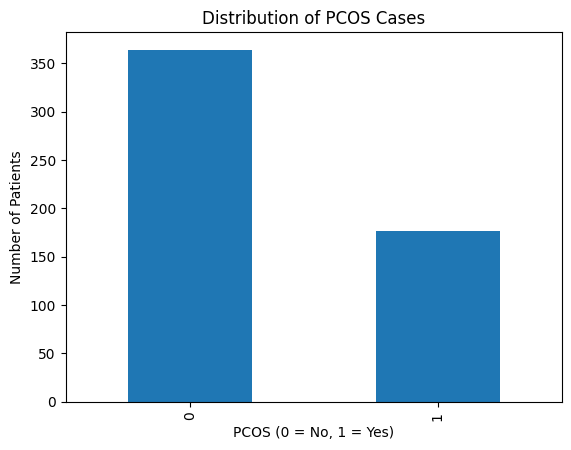

In [9]:

df["PCOS (Y/N)"].value_counts().plot(
    kind="bar",
    title="Distribution of PCOS Cases",
    xlabel="PCOS (0 = No, 1 = Yes)",
    ylabel="Number of Patients"
)

In [10]:
# Remove unnecessary columns
df.drop(columns=["Sl. No", "Patient File No.", "Unnamed: 44"],
        inplace=True)

# Check the updated dataset
df.shape

(541, 42)

In [11]:
# Check missing values in each column
df.isnull().sum()[df.isnull().sum() > 0]

,0
Marraige Status (Yrs),1
Fast food (Y/N),1


In [12]:
# Fill missing marriage duration with the median
df["Marraige Status (Yrs)"] = df["Marraige Status (Yrs)"].fillna(
    df["Marraige Status (Yrs)"].median()
)

# Fill missing fast-food values with the most common value
df["Fast food (Y/N)"] = df["Fast food (Y/N)"].fillna(
    df["Fast food (Y/N)"].mode()[0]
)

# Check whether any missing values remain
df.isnull().sum()[df.isnull().sum() > 0]

,0


In [13]:
# Display the data type of each column
df.dtypes

,0
PCOS (Y/N),int64
Age (yrs),int64
Weight (Kg),float64
Height(Cm),float64
BMI,float64
Blood Group,int64
Pulse rate(bpm),int64
RR (breaths/min),int64
Hb(g/dl),float64
Cycle(R/I),int64


In [14]:
# Check for duplicate rows after cleaning
df.duplicated().sum()

np.int64(0)

In [15]:
# Display summary statistics for numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PCOS (Y/N),541.0,0.327172,0.469615,0.000000,0.000000,0.000000,1.000000,1.000000
Age (yrs),541.0,31.430684,5.411006,20.000000,28.000000,31.000000,35.000000,48.000000
Weight (Kg),541.0,59.637153,11.028287,31.000000,52.000000,59.000000,65.000000,108.000000
Height(Cm),541.0,156.484835,6.033545,137.000000,152.000000,156.000000,160.000000,180.000000
BMI,541.0,24.311285,4.056399,12.417882,21.641274,24.238227,26.634958,38.900000
Blood Group,541.0,13.802218,1.840812,11.000000,13.000000,14.000000,15.000000,18.000000
Pulse rate(bpm),541.0,73.247689,4.430285,13.000000,72.000000,72.000000,74.000000,82.000000
RR (breaths/min),541.0,19.243993,1.688629,16.000000,18.000000,18.000000,20.000000,28.000000
Hb(g/dl),541.0,11.160037,0.866904,8.500000,10.500000,11.000000,11.700000,14.800000
Cycle(R/I),541.0,2.560074,0.901950,2.000000,2.000000,2.000000,4.000000,5.000000


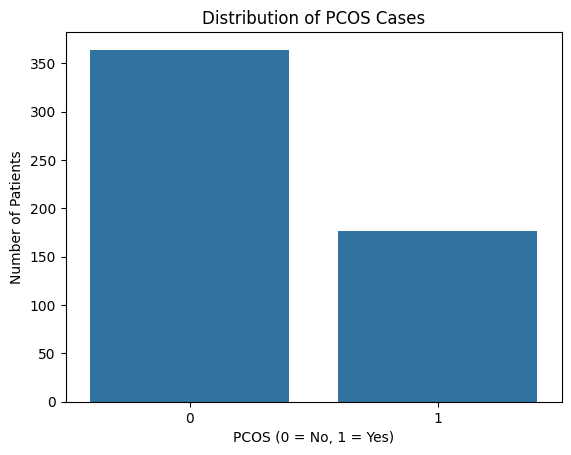

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="PCOS (Y/N)")

plt.title("Distribution of PCOS Cases")
plt.xlabel("PCOS (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.show()

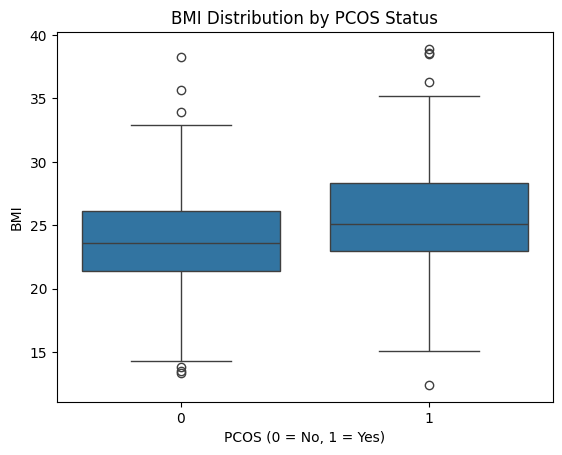

In [18]:
# Compare BMI between PCOS-positive and PCOS-negative patients
sns.boxplot(data=df, x="PCOS (Y/N)", y="BMI")

plt.title("BMI Distribution by PCOS Status")
plt.xlabel("PCOS (0 = No, 1 = Yes)")
plt.ylabel("BMI")
plt.show()

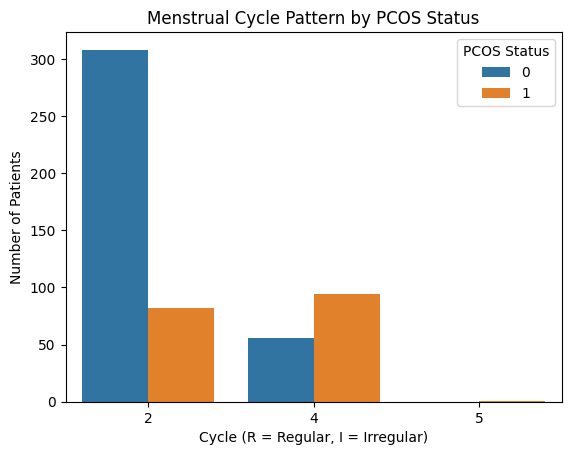

In [19]:
# Compare menstrual cycle patterns across PCOS groups
sns.countplot(data=df, x="Cycle(R/I)", hue="PCOS (Y/N)")

plt.title("Menstrual Cycle Pattern by PCOS Status")
plt.xlabel("Cycle (R = Regular, I = Irregular)")
plt.ylabel("Number of Patients")
plt.legend(title="PCOS Status")
plt.show()

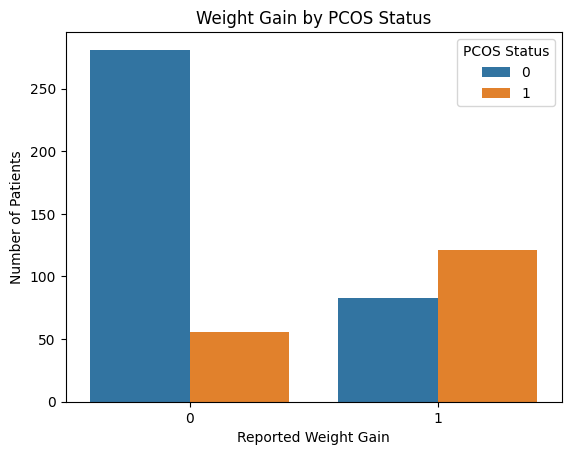

In [20]:
# Compare reported weight gain across PCOS groups
sns.countplot(data=df, x="Weight gain(Y/N)", hue="PCOS (Y/N)")

plt.title("Weight Gain by PCOS Status")
plt.xlabel("Reported Weight Gain")
plt.ylabel("Number of Patients")
plt.legend(title="PCOS Status")
plt.show()

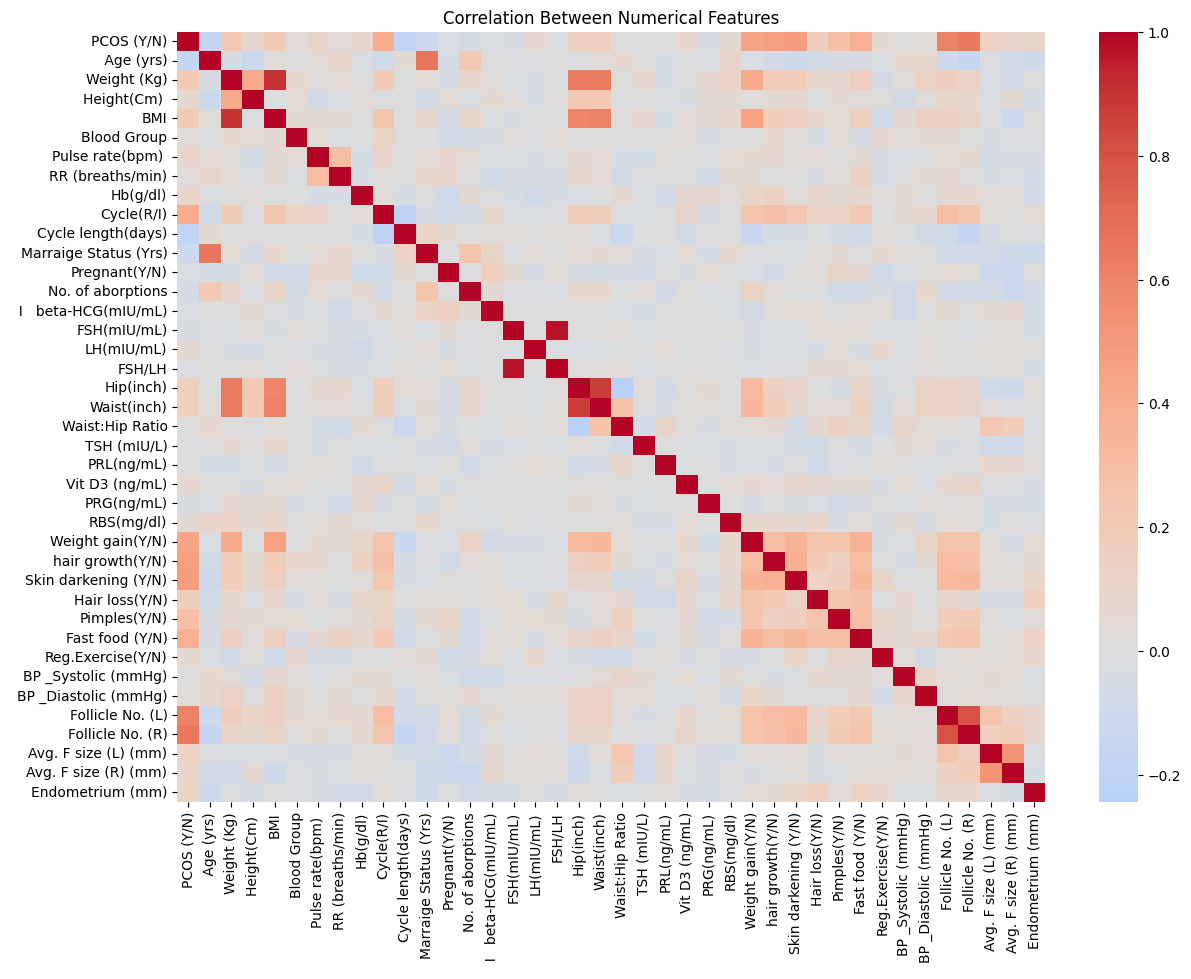

In [22]:
num_df = df.select_dtypes(include="number")

#correlation matrix
plt.figure(figsize=(14, 10))
sns.heatmap(num_df.corr(), cmap="coolwarm", center=0)

plt.title("Correlation Between Numerical Features")
plt.show()

In [24]:
X = df.drop(columns=["PCOS (Y/N)"])
y = df["PCOS (Y/N)"]

# Check the dimensions
print("Features:", X.shape)
print("Target:", y.shape)

Features: (541, 41)
Target: (541,)


In [25]:
X = pd.get_dummies(X, drop_first=True)

print("Features after encoding:", X.shape)

Features after encoding: (541, 541)


In [26]:
#training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 432
Testing records: 109


In [27]:
# Scale numerical features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

#models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "SVM": SVC(),
    "XGBoost": XGBClassifier(
        n_estimators=100,
        random_state=42,
        eval_metric="logloss"
    )
}

In [29]:
#evaluation metrics
from sklearn.metrics import accuracy_score, classification_report

results = {}

for name, model in models.items():

    # Use scaled data for Logistic Regression and SVM
    if name in ["Logistic Regression", "SVM"]:
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

    # Calculate test accuracy
    accuracy = accuracy_score(y_test, predictions)
    results[name] = accuracy

    print(f"\n{name}")
    print(f"Accuracy: {accuracy:.4f}")
    print(classification_report(y_test, predictions, zero_division=0))


Logistic Regression
Accuracy: 0.8807
              precision    recall  f1-score   support

           0       0.89      0.93      0.91        73
           1       0.85      0.78      0.81        36

    accuracy                           0.88       109
   macro avg       0.87      0.85      0.86       109
weighted avg       0.88      0.88      0.88       109


Random Forest
Accuracy: 0.8624
              precision    recall  f1-score   support

           0       0.85      0.96      0.90        73
           1       0.89      0.67      0.76        36

    accuracy                           0.86       109
   macro avg       0.87      0.81      0.83       109
weighted avg       0.87      0.86      0.86       109


SVM
Accuracy: 0.8073
              precision    recall  f1-score   support

           0       0.80      0.95      0.87        73
           1       0.83      0.53      0.64        36

    accuracy                           0.81       109
   macro avg       0.81      0.74   

In [30]:
# Compare the accuracy of all models
results_df = pd.DataFrame(
    list(results.items()),
    columns=["Model", "Accuracy"]
)

results_df = results_df.sort_values(
    by="Accuracy", ascending=False
)

display(results_df)

,Model,Accuracy
3,XGBoost,0.926606
0,Logistic Regression,0.880734
1,Random Forest,0.862385
2,SVM,0.807339


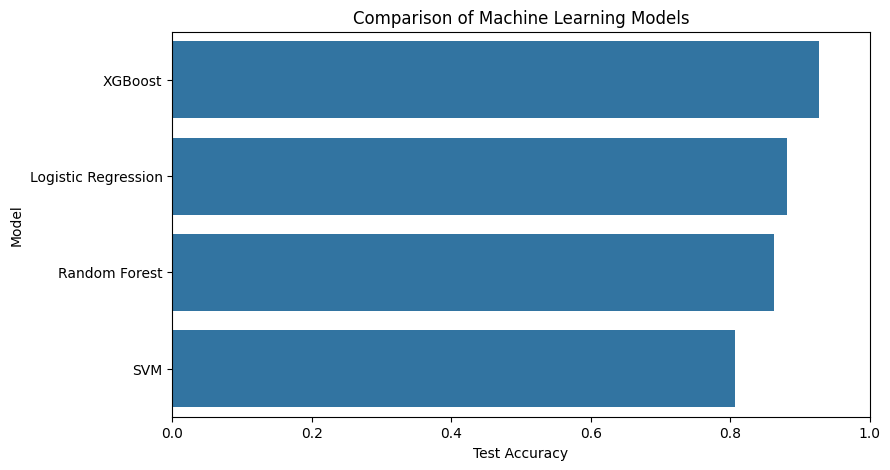

In [31]:
# Plot model accuracy
plt.figure(figsize=(9, 5))

sns.barplot(data=results_df, x="Accuracy", y="Model")

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Test Accuracy")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.show()

In [32]:
# Select the model with the highest test accuracy
best_model_name = max(results, key=results.get)
best_model = models[best_model_name]

print("Best model:", best_model_name)
print("Test accuracy:", round(results[best_model_name] * 100, 2), "%")

Best model: XGBoost
Test accuracy: 92.66 %


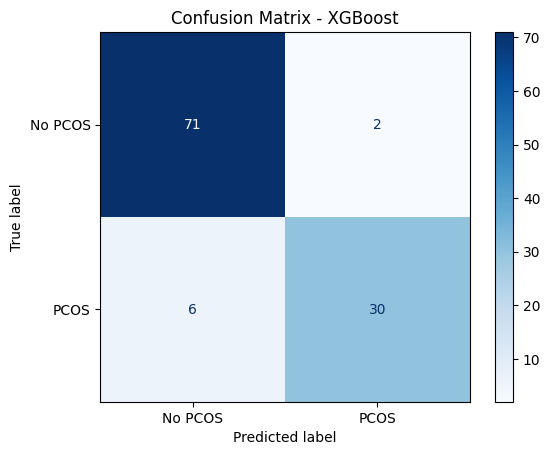

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

if best_model_name in ["Logistic Regression", "SVM"]:
    y_pred = best_model.predict(X_test_scaled)
else:
    y_pred = best_model.predict(X_test)

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No PCOS", "PCOS"]
)

display.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Model:", best_model_name)
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 3))

Model: XGBoost
Accuracy: 92.66 %
Precision: 0.938
Recall: 0.833
F1-score: 0.882


In [41]:
# Predict PCOS for a random patient

# Select a random patient
i = np.random.randint(len(X))

patient = X.iloc[[i]]
actual = y.iloc[i]

# Make prediction
if best_model_name in ["Logistic Regression", "SVM"]:
    patient_input = scaler.transform(patient)
    pred = best_model.predict(patient_input)[0]
else:
    pred = best_model.predict(patient)[0]

# Display results
print("PCOS Prediction")
print("--------------------")
print("Actual result:", "PCOS Positive" if actual == 1 else "PCOS Negative")
print("Predicted result:", "PCOS Positive" if pred == 1 else "PCOS Negative")
print("Correct prediction:", "Yes" if actual == pred else "No")

PCOS Prediction
--------------------
Actual result: PCOS Negative
Predicted result: PCOS Negative
Correct prediction: Yes
